**PROJECT 34:**

Jaakko Hietikko 2214871

Jani-Matti Laasonen Y68417011

Urho Väyrynen 2214968

**1. Data Exploration and Preprocessing:** Explore the distribution of tweets by sentiment, Age of User,
Country, and Time of Tweet. Visualize the data using appropriate charts such as bar charts, histograms,
and heatmaps. 

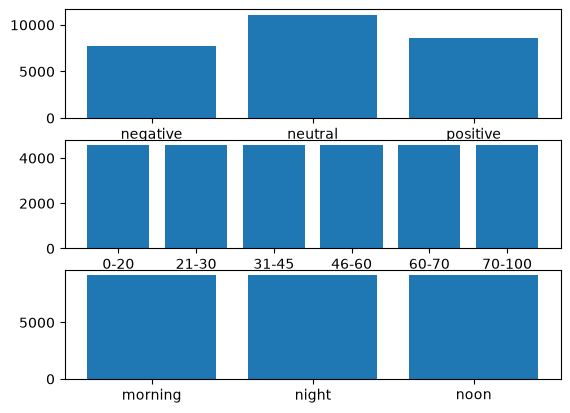

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

data = pd.read_csv("train.csv", encoding="latin1")
data_sentiment = data["sentiment"]
data_age_of_user = data["Age of User"]
data_country = data["Country"]
data_time_of_tweet = data["Time of Tweet"]
data_density = data["Density (P/Km²)"]
y = data_sentiment.value_counts().sort_index()
z = data_age_of_user.value_counts().sort_index()
x = data_country.value_counts().sort_index()
i = data_time_of_tweet.value_counts().sort_index()
j = data_density.value_counts().sort_index()

fig, ax = plt.subplots(3)

ax[0].bar(y.index, y.values)
ax[1].bar(z.index, z.values)
ax[2].bar(i.index, i.values)

plt.show()

country_df = x.rename_axis("Country").reset_index(name="Count")

fig = px.choropleth(
    country_df,
    locations="Country",
    locationmode="country names",
    color="Count",
    hover_name="Country",
    color_continuous_scale="Viridis",
    title="Number of Instances per Country"
)

fig.show()

**2. Exploratory Analysis of Demographics:** Analyze the correlation between demographic
information (e.g., Age of User, Country) and the sentiment of the tweets. Identify if certain age groups
or countries tend to express more positive, negative, or neutral sentiments. Also. analyze how density
affects sentiment patterns.

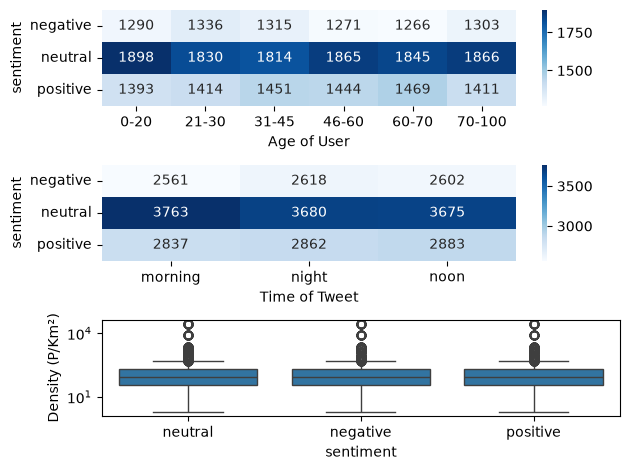

Spearman correlation between sentiment and time of tweet: 0.000
P-value: 0.9477
Spearman correlation between sentiment and age of user: 0.006
P-value: 0.3156
Spearman correlation between sentiment and density: 0.003
P-value: 0.5747


In [2]:
import numpy as np
import seaborn as sns
from scipy.stats import spearmanr

cross_table = pd.crosstab(data_sentiment, data_age_of_user)
cross_table2 = pd.crosstab(data_sentiment, data_time_of_tweet)
cross_table3 = pd.crosstab(data_sentiment, data_density)

fig, ax = plt.subplots(3)

sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", ax=ax[0])
sns.heatmap(cross_table2, annot=True, fmt="d", cmap="Blues", ax=ax[1])
sns.boxplot(data=data, x="sentiment",y="Density (P/Km²)", ax=ax[2])
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

def correlation(data1, data2, subject1, subject2):
    rho, p_value = spearmanr(
        data1,
        data2,
        nan_policy="omit"
    )
    
    print(f"Spearman correlation between {subject1} and {subject2}: {rho:.3f}")
    print(f"P-value: {p_value:.4f}")

correlation(data["sentiment"], data["Time of Tweet"], "sentiment", "time of tweet")
correlation(data["sentiment"], data["Age of User"], "sentiment", "age of user")
correlation(data["sentiment"], data["Density (P/Km²)"], "sentiment", "density")